In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
X,y = make_classification(
    n_samples = 900,
    n_features = 2,
    n_informative = 2,
    n_redundant=0,
    n_repeated=0,
    n_classes=3,
    n_clusters_per_class=1,
    class_sep=1.15,
    flip_y=0.06,
    random_state=42
)

X_train,X_test,y_train,y_test = train_test_split(X,y,
                                                 test_size=0.25,
                                                 random_state=42,
                                                 stratify=y)

In [ ]:
model = RandomForestClassifier(
    n_estimators=160,
    max_features=2,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=1
)

model.fit(X_train,y_train)

RandomForestClassifier(max_features=2, n_estimators=160, n_jobs=1,
                       oob_score=True, random_state=42)

In [ ]:
test_pred = model.predict(X_test)

print(f'test accuracy: {accuracy_score(y_test,test_pred):.3f}')
print(f'Out_of_bag accuracy: {model.oob_score_:.3f}')

In [ ]:
x_min,x_max = X[:,0].min() -0.6, X[:,0].max() +0.6
y_min,y_max = X[:,1].min()-0.6, X[:,1].max() + 0.6

xx,yy = np.meshgrid(
    np.linspace(x_min,x_max,360),
    np.linspace(y_min,y_max,360)
)
grid = np.c_[xx.ravel(),yy.ravel()]

In [ ]:
tree_predictions = np.array([
    tree.predict(grid) for tree in model.estimators_
])

classes = model.classes_
vote_ratio = np.stack(
    [(tree_predictions == cls).mean(axis=0) for cls in classes],
     axis=1)
final_class = vote_ratio.argmax(axis=1)

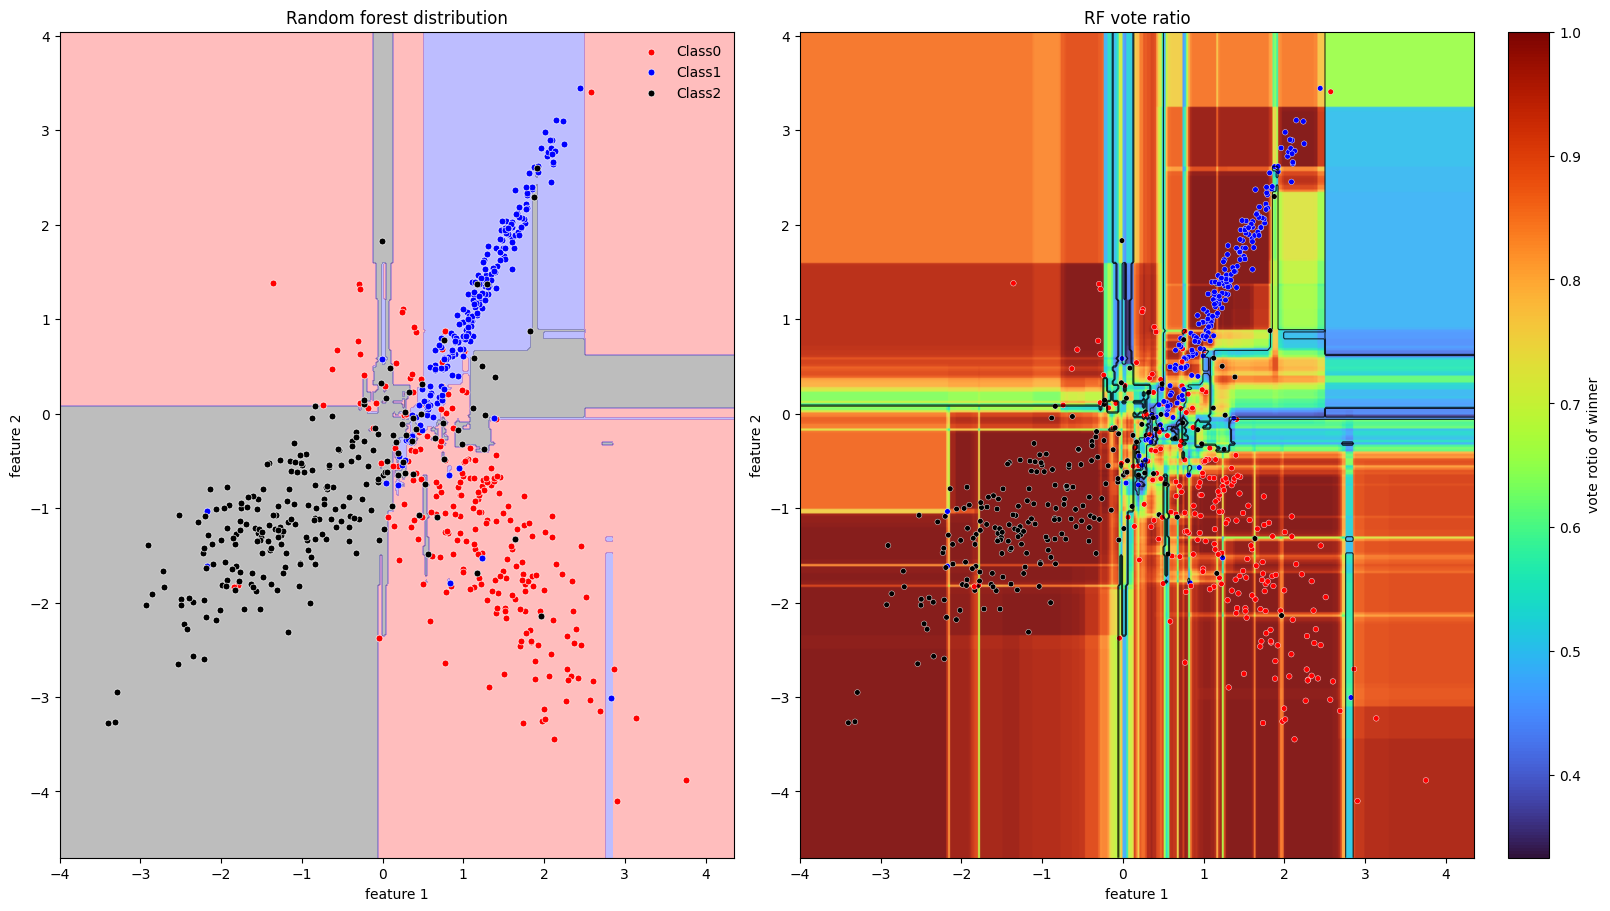

In [ ]:
colors = ['red','blue','black']
cmap = plt.matplotlib.colors.ListedColormap(colors)

fig, axes = plt.subplots(1,2,figsize=(16,9),constrained_layout=True)

axes[0].contourf(
    xx,yy, final_class.reshape(xx.shape),
    levels = np.arange(len(classes)+1) - 0.5,
    cmap = cmap, alpha=0.26
)

for cls,color in zip(classes,colors):
  mask = y_train ==cls
  axes[0].scatter(
      X_train[mask,0], X_train[mask,1],
      c=color, edgecolors='white',linewidths=0.45,
      s=24,label = f'Class{cls}'
  )

axes[0].set_title('Random forest distribution')
axes[0].set_xlabel('feature 1')
axes[0].set_ylabel('feature 2')
axes[0].legend(frameon=False)

#dominant vote
dominant_vote = vote_ratio.max(axis=1)
axes[1].imshow(
    dominant_vote.reshape(xx.shape),
    origin = 'lower',
    extent = (x_min,x_max,y_min,y_max),
    cmap = 'turbo',
    vmin = 1/len(classes),
    vmax = 1,
    aspect = 'auto',
    alpha = 0.9
)

axes[1].contour(
    xx,yy,final_class.reshape(xx.shape),
    levels = np.arange(len(classes)+1)-0.5,
    colors = 'black',linewidths=0.8,alpha=0.8
)
axes[1].scatter(
    X_train[:,0],X_train[:,1],
    c=y_train,cmap=cmap,edgecolors='white',
    linewidths = 0.3,s=16
)
axes[1].set_title("RF vote ratio")
axes[1].set_xlabel("feature 1")
axes[1].set_ylabel("feature 2")
colorbar = fig.colorbar(
    plt.cm.ScalarMappable(
        norm = plt.Normalize(vmin=1/len(classes),vmax=1),
        cmap = 'turbo'
    ),
    ax=axes[1]
)

colorbar.set_label('vote rotio of winner')

plt.show()